# Analisis Curah Hujan ERA5 (Copernicus CDS) - Kota Semarang

Notebook ini digunakan untuk memproses, menganalisis, dan memvisualisasikan data curah hujan reanalisis **ERA5** dari **Copernicus Climate Data Store (CDS)** yang telah disesuaikan dengan zona waktu lokal Indonesia (**WIB / UTC+7**).

### Fitur Analisis:
- **Lokasi Target**: Kota Semarang, Jawa Tengah, Indonesia (Lat `-6.99`, Lon `110.42`)
- **Variabel ERA5**: `tp` (*Total Precipitation*)
- **Konversi Satuan**: Meter (m) $\rightarrow$ Milimeter (mm) (dikalikan $1000$)
- **Konversi Waktu**: UTC $\rightarrow$ **WIB (UTC+7)** dengan offset `+ pd.Timedelta(hours=7)`
- **Fleksibilitas Input**: Mendukung path spesifik (drag & drop), auto-scan folder, atau ekstraksi otomatis `.zip`.

## 1. Import Library yang Dibutuhkan

In [1]:
import os
import glob
import zipfile
import xarray as xr
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# Setting plot matplotlib inline
%matplotlib inline
plt.rcParams['figure.dpi'] = 150
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'

print("Pustaka berhasil dimuat:")
print(f"- xarray    : {xr.__version__}")
print(f"- pandas    : {pd.__version__}")

Pustaka berhasil dimuat:
- xarray    : 2026.9.0
- pandas    : 3.1.1


## 2. Pengaturan Lokasi File Data (Fleksibel & Drag-and-Drop)

Anda dapat menentukan path file `.nc` atau `.zip` di variabel `file_path` di bawah. Jika dibiarkan kosong (`""`), sistem akan otomatis mencari file di folder kerja saat ini.

In [2]:
# Masukkan path file .nc langsung (bisa copy-paste / drag & drop path ke sini):
# Contoh: file_path = "data_stream-oper_stepType-accum.nc"
#         file_path = "/home/alpa_arch/Downloads/data_stream-oper_stepType-accum.nc"
# Jika dikosongkan (""), notebook akan otomatis memindai folder lokal saat ini.
file_path = "data_stream-oper_stepType-accum.nc"

import urllib.parse

def clean_path(raw_path: str) -> str:
    """Membersihkan string path dari tanda kutip, format URI, URL encoding (%20), dan escaped space."""
    if not raw_path:
        return ""
    p = raw_path.strip()
    if p.startswith("file://"):
        p = p[7:]
        p = urllib.parse.unquote(p)
    if (p.startswith("'") and p.endswith("'")) or (p.startswith('"') and p.endswith('"')):
        p = p[1:-1].strip()
    if "%" in p:
        p_unquoted = urllib.parse.unquote(p)
        if os.path.exists(p_unquoted) or not os.path.exists(p):
            p = p_unquoted
    if "\\" in p and not os.path.exists(p):
        p_unescaped = p.replace(r"\ ", " ")
        if os.path.exists(p_unescaped):
            p = p_unescaped
    return os.path.expanduser(p)

def resolve_nc_files(custom_path: str = "", data_dir: str = ".") -> list[str]:
    """Membuka file .nc secara langsung dari path agar proses cepat."""
    cleaned = clean_path(custom_path)
    if cleaned and os.path.exists(cleaned):
        if os.path.isfile(cleaned):
            if cleaned.lower().endswith(".nc"):
                print(f"[INFO] Langsung menggunakan file .nc: '{cleaned}'")
                return [cleaned]
            elif cleaned.lower().endswith(".zip"):
                print(f"[INFO] Mengekstrak zip dari: {cleaned}")
                with zipfile.ZipFile(cleaned, 'r') as z:
                    z.extractall(data_dir)
                return sorted(glob.glob(os.path.join(data_dir, "*.nc")))
        elif os.path.isdir(cleaned):
            return resolve_nc_files("", data_dir=cleaned)

    # Fallback auto-scan folder lokal jika path kosong
    nc_files = sorted(glob.glob(os.path.join(data_dir, "*.nc")))
    if nc_files:
        print(f"[INFO] Menggunakan file .nc di folder lokal: '{nc_files[0]}'")
        return [nc_files[0]]

    zip_files = sorted(glob.glob(os.path.join(data_dir, "*.zip")))
    if zip_files:
        print(f"[INFO] Ditemukan file .zip lokal: {zip_files[0]}. Mengekstrak...")
        with zipfile.ZipFile(zip_files[0], 'r') as z:
            z.extractall(data_dir)
        return sorted(glob.glob(os.path.join(data_dir, "*.nc")))

    return []

nc_files = resolve_nc_files(file_path)
if nc_files:
    print(f"[OK] Siap membaca {len(nc_files)} file .nc:")
    for f in nc_files:
        print(f"  - {f}")
else:
    print("=" * 70)
    print("Silakan letakkan file .nc hasil unduhan Copernicus ke dalam folder ini")
    print("=" * 70)

[INFO] Langsung menggunakan file .nc: 'data_stream-oper_stepType-accum.nc'
[OK] Siap membaca 1 file .nc:
  - data_stream-oper_stepType-accum.nc


## 3. Membaca Dataset dengan `xarray`

In [3]:
if not nc_files:
    print("Silakan letakkan file .nc hasil unduhan Copernicus ke dalam folder ini")
    ds = None
else:
    if len(nc_files) == 1:
        ds = xr.open_dataset(nc_files[0])
    else:
        ds = xr.open_mfdataset(nc_files, combine='by_coords')
    
    print("Metadata Dataset ERA5:")
    print(ds)

Metadata Dataset ERA5:
<xarray.Dataset> Size: 525kB
Dimensions:     (valid_time: 7296, latitude: 3, longitude: 4)
Coordinates:
  * valid_time  (valid_time) datetime64[ns] 58kB 2026-01-01 ... 2026-10-31T23...
    expver      (valid_time) <U4 117kB ...
  * latitude    (latitude) float64 24B -6.75 -7.0 -7.25
  * longitude   (longitude) float64 32B 110.0 110.2 110.5 110.8
    number      int64 8B ...
Data variables:
    tp          (valid_time, latitude, longitude) float32 350kB ...
Attributes:
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts
    history:                 2026-11-11T11:43 GRIB to CDM+CF via cfgrib-0.9.1...


## 4. Ekstraksi Titik Semarang, Konversi Satuan (mm), dan Konversi Waktu ke WIB (UTC+7)

- **Target Koordinat**: Lat `-6.99`, Lon `110.42` (*Nearest Neighbor*)
- **Konversi Curah Hujan**: $1 \text{ meter} = 1000 \text{ mm}$
- **Konversi Waktu**: $\text{Waktu (WIB)} = \text{Waktu (UTC)} + 7 \text{ jam}$ (`pd.Timedelta(hours=7)`)

In [4]:
TARGET_LAT = -6.99
TARGET_LON = 110.42

if ds is None:
    print("Silakan letakkan file .nc hasil unduhan Copernicus ke dalam folder ini")
    df_rain = None
else:
    # Deteksi koordinat spasial
    lat_key = 'latitude' if 'latitude' in ds.coords else ('lat' if 'lat' in ds.coords else None)
    lon_key = 'longitude' if 'longitude' in ds.coords else ('lon' if 'lon' in ds.coords else None)

    # Menyesuaikan sistem bujur 0..360 jika ada
    search_lon = TARGET_LON
    lon_vals = ds[lon_key].values
    if lon_vals.min() >= 0 and TARGET_LON < 0:
        search_lon = TARGET_LON % 360
    elif lon_vals.max() > 180 and TARGET_LON < 0:
        search_lon = (TARGET_LON + 360) % 360

    # Ekstraksi titik terdekat
    sel_kwargs = {lat_key: TARGET_LAT, lon_key: search_lon}
    point_ds = ds.sel(method='nearest', **sel_kwargs)

    actual_lat = float(point_ds[lat_key].values)
    actual_lon = float(point_ds[lon_key].values)
    print(f"Target Koordinat : Lat {TARGET_LAT}, Lon {TARGET_LON}")
    print(f"Grid ERA5 Terdekat: Lat {actual_lat:.4f}, Lon {actual_lon:.4f}")

    # Deteksi nama variabel curah hujan ('tp' / 'total_precipitation')
    tp_var = 'tp' if 'tp' in point_ds.data_vars else ('total_precipitation' if 'total_precipitation' in point_ds.data_vars else None)
    if not tp_var:
        for var in point_ds.data_vars:
            if 'precip' in var.lower() or 'tp' in var.lower():
                tp_var = var
                break
        if not tp_var:
            tp_var = list(point_ds.data_vars.keys())[0]

    # Deteksi sumbu waktu
    rain_da = point_ds[tp_var]
    time_key = 'valid_time' if 'valid_time' in rain_da.coords else ('time' if 'time' in rain_da.coords else None)

    # Konversi meter -> milimeter (x 1000)
    rain_series_mm = (rain_da.to_series() * 1000.0).clip(lower=0.0)
    df_raw = rain_series_mm.reset_index()
    df_raw = df_raw.rename(columns={tp_var: 'Curah_Hujan_mm'})

    # Konversi waktu ke WIB (UTC+7)
    df_raw['Waktu_UTC'] = pd.to_datetime(df_raw[time_key])
    df_raw['Waktu_WIB'] = df_raw['Waktu_UTC'] + pd.Timedelta(hours=7)
    df_rain = df_raw[['Waktu_WIB', 'Curah_Hujan_mm']].sort_values('Waktu_WIB').reset_index(drop=True)

    print("\nPreview Data Curah Hujan (WIB):")
    display(df_rain.head(10))

Target Koordinat : Lat -6.99, Lon 110.42
Grid ERA5 Terdekat: Lat -7.0000, Lon 110.5000

Preview Data Curah Hujan (WIB):


,Waktu_WIB,Curah_Hujan_mm
0,2026-01-01 07:00:00,0.012398
1,2026-01-01 08:00:00,0.268459
2,2026-01-01 09:00:00,0.021935
3,2026-01-01 10:00:00,0.039101
4,2026-01-01 11:00:00,0.089169
5,2026-01-01 12:00:00,0.089169
6,2026-01-01 13:00:00,0.145912
7,2026-01-01 14:00:00,0.375748
8,2026-01-01 15:00:00,0.344276
9,2026-01-01 16:00:00,0.933170


## 5. Visualisasi Data (Waktu Berbasis WIB)

### A. Grafik Deret Waktu Per Jam (*Hourly Time Series*)

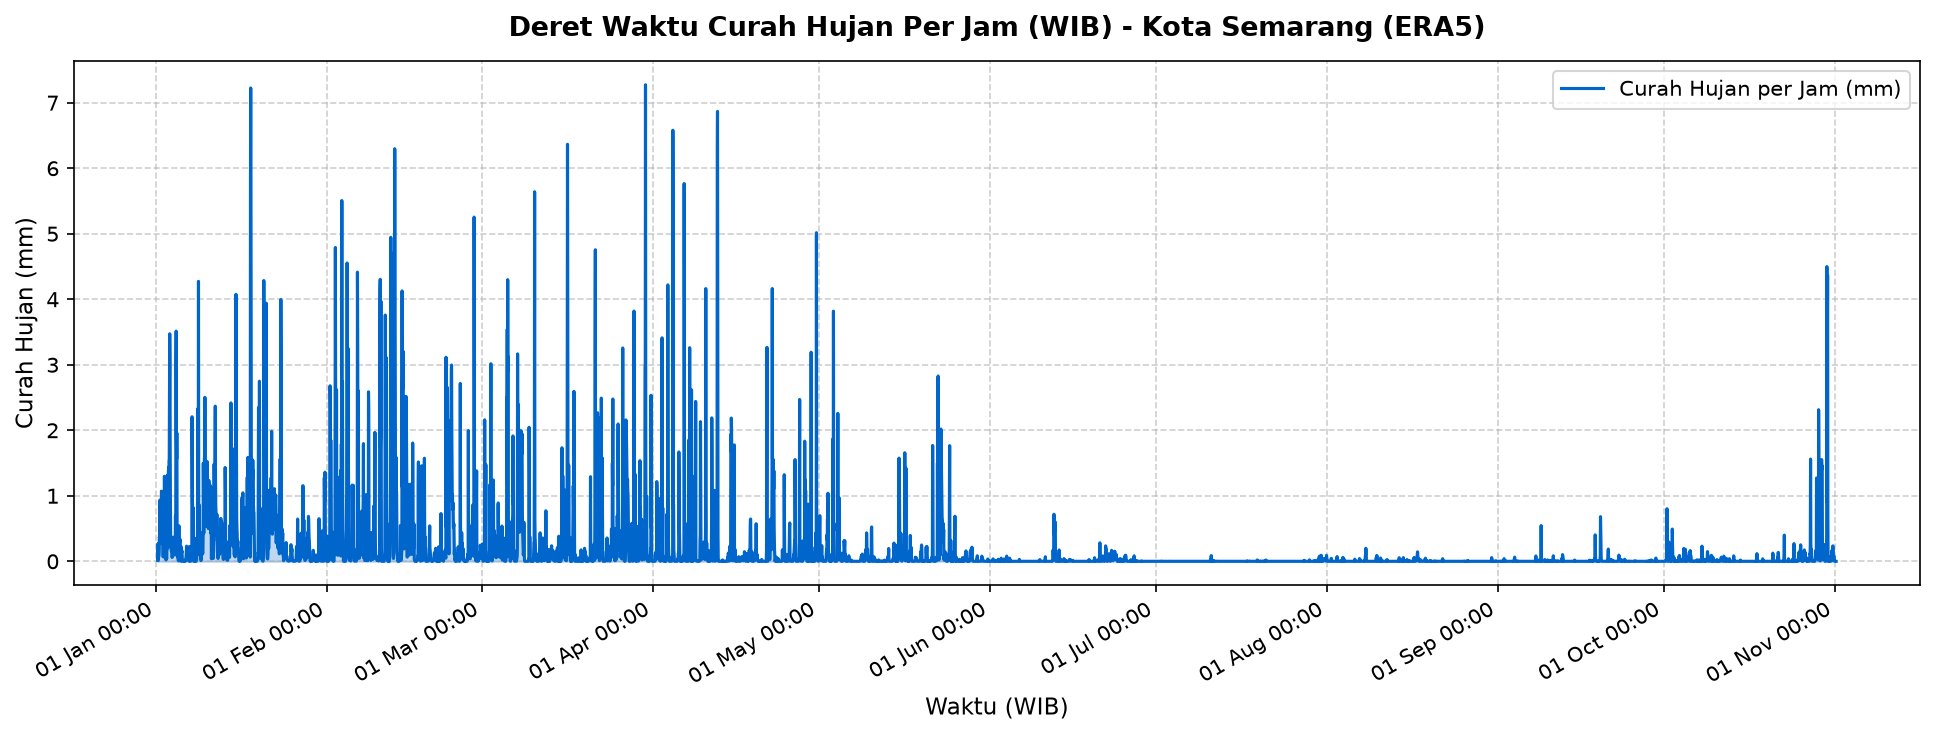

In [5]:
if df_rain is not None:
    fig, ax = plt.subplots(figsize=(13, 5))
    ax.plot(df_rain['Waktu_WIB'], df_rain['Curah_Hujan_mm'], color='#0066cc', linewidth=1.5, label='Curah Hujan per Jam (mm)')
    ax.fill_between(df_rain['Waktu_WIB'], df_rain['Curah_Hujan_mm'], color='#0066cc', alpha=0.25)

    ax.set_title('Deret Waktu Curah Hujan Per Jam (WIB) - Kota Semarang (ERA5)', fontsize=13, fontweight='bold', pad=12)
    ax.set_xlabel('Waktu (WIB)', fontsize=11)
    ax.set_ylabel('Curah Hujan (mm)', fontsize=11)
    ax.grid(True, linestyle='--', alpha=0.6)
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%d %b %H:%M'))
    fig.autofmt_xdate()
    ax.legend(loc='upper right')
    plt.tight_layout()
    plt.savefig('curah_hujan_semarang_hourly.png', dpi=300)
    plt.show()
else:
    print("Silakan letakkan file .nc hasil unduhan Copernicus ke dalam folder ini")

### B. Grafik Bar Total Akumulasi Hujan Per Hari (*Daily Accumulation*)

/tmp/ipykernel_260593/2050173846.py:26: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(df_daily['Tanggal_WIB'].dt.strftime('%d-%m-%Y'), rotation=45, ha='right')


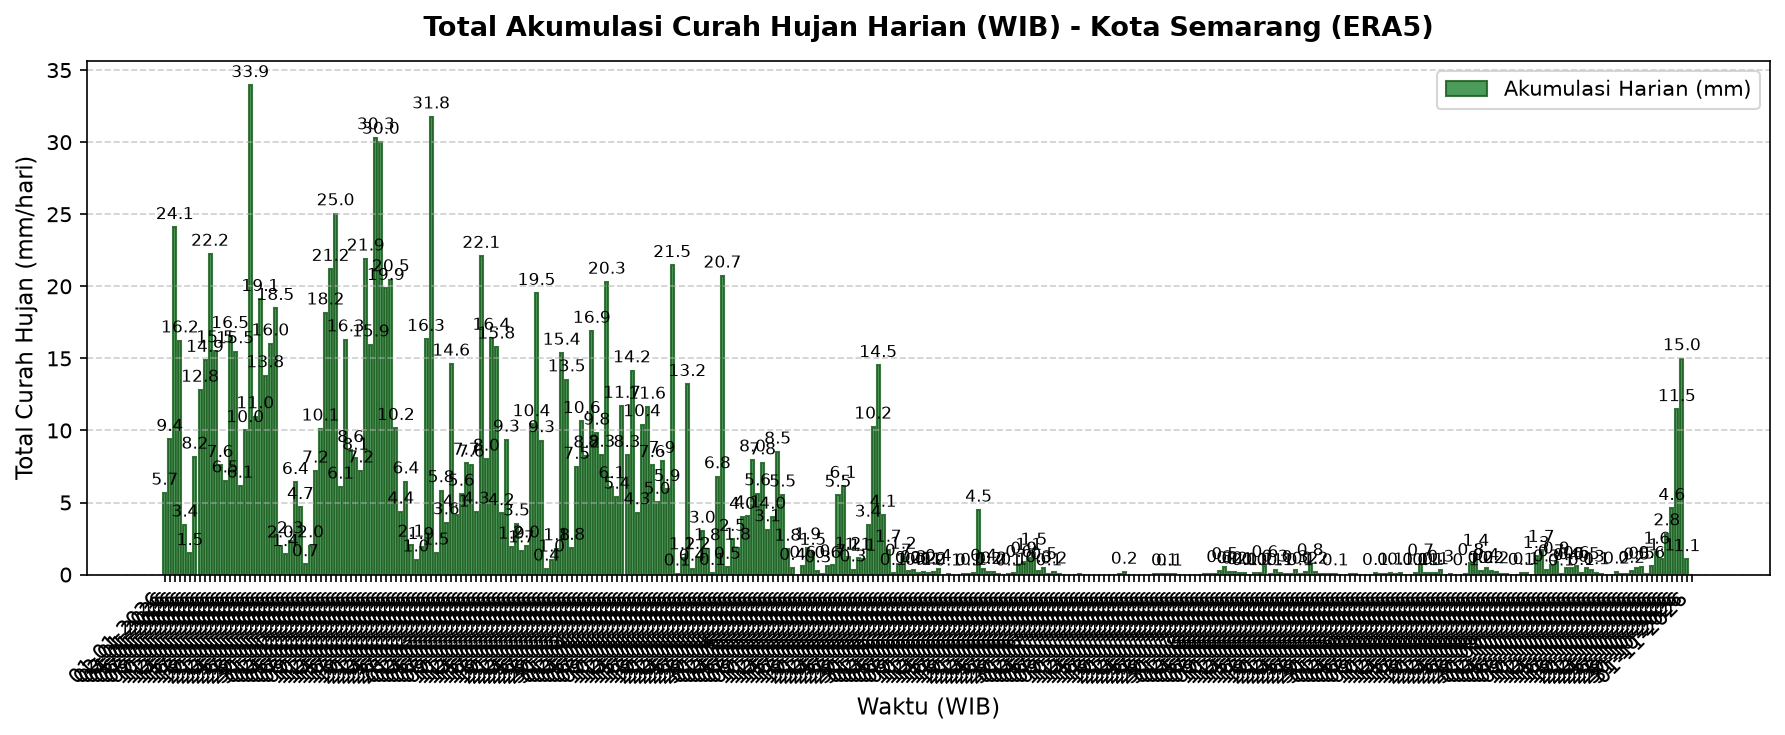

In [6]:
if df_rain is not None:
    # Agregasi akumulasi harian berbasis Waktu_WIB
    df_daily = df_rain.set_index('Waktu_WIB').resample('1D')['Curah_Hujan_mm'].sum().reset_index()
    df_daily = df_daily.rename(columns={'Waktu_WIB': 'Tanggal_WIB', 'Curah_Hujan_mm': 'Total_Hujan_Harian_mm'})

    fig, ax = plt.subplots(figsize=(12, 5))
    bars = ax.bar(
        df_daily['Tanggal_WIB'].dt.strftime('%d-%m-%Y'),
        df_daily['Total_Hujan_Harian_mm'],
        color='#2b8a3e',
        edgecolor='#1b5e20',
        width=0.6,
        alpha=0.85,
        label='Akumulasi Harian (mm)'
    )

    # Label angka di atas bar
    for bar in bars:
        height = bar.get_height()
        if height > 0.05:
            ax.text(bar.get_x() + bar.get_width() / 2.0, height + 0.3, f"{height:.1f}", ha='center', va='bottom', fontsize=8)

    ax.set_title('Total Akumulasi Curah Hujan Harian (WIB) - Kota Semarang (ERA5)', fontsize=13, fontweight='bold', pad=12)
    ax.set_xlabel('Waktu (WIB)', fontsize=11)
    ax.set_ylabel('Total Curah Hujan (mm/hari)', fontsize=11)
    ax.set_xticklabels(df_daily['Tanggal_WIB'].dt.strftime('%d-%m-%Y'), rotation=45, ha='right')
    ax.grid(axis='y', linestyle='--', alpha=0.6)
    ax.legend(loc='upper right')
    plt.tight_layout()
    plt.savefig('curah_hujan_semarang_daily.png', dpi=300)
    plt.show()
else:
    print("Silakan letakkan file .nc hasil unduhan Copernicus ke dalam folder ini")

## 6. Menyimpan Hasil Ekstraksi ke File CSV

In [7]:
if df_rain is not None:
    csv_path = "curah_hujan_semarang.csv"
    df_rain.to_csv(csv_path, index=False)
    print(f"[BERHASIL] Data disimpan ke: '{csv_path}' dengan kolom 'Waktu_WIB'")
    print("\nRingkasan Statistik (mm):")
    print(df_rain['Curah_Hujan_mm'].describe())
else:
    print("Silakan letakkan file .nc hasil unduhan Copernicus ke dalam folder ini")

[BERHASIL] Data disimpan ke: 'curah_hujan_semarang.csv' dengan kolom 'Waktu_WIB'

Ringkasan Statistik (mm):
count    7296.000000
mean        0.180373
std         0.563027
min         0.000000
25%         0.000000
50%         0.003338
75%         0.077248
max         7.273197
Name: Curah_Hujan_mm, dtype: float64
